Módulo 3: ANN que recomienda la acción preventiva
1. Preparación

Traemos las herramientas del programa: las de siempre para tablas y gráficos, y tres de scikit-learn para preparar los datos de la red.

In [1]:
import numpy as np                  # cálculos con números
import pandas as pd                 # tablas
import matplotlib.pyplot as plt     # gráficos
import seaborn as sns               # gráficos más bonitos

from sklearn.model_selection import GroupShuffleSplit    # separa entrenamiento y prueba por grupos
from sklearn.preprocessing import LabelEncoder, StandardScaler   # convierte nombres en números / pone los números en la misma escala
from sklearn.utils.class_weight import compute_class_weight      # calcula cuánto pesa cada clase

sns.set_theme(style="whitegrid")    # fondo con cuadrícula

Cargar los datos

In [2]:
acc = pd.read_csv("../data/raw/vectoria_acciones.csv", parse_dates=["fecha_inicio_semana"])   # abre el archivo
print(acc.shape)    # (filas, columnas)
acc.head()          # primeras 5 filas

(2060, 12)


,fecha_inicio_semana,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
0,2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
1,2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2,2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
3,2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
4,2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal


Definir qué entra y qué sale

Qué se analiza: decidimos qué datos le damos a la red (entradas) y qué queremos que adivine (salida).

Entradas (7 columnas): los casos predichos, el umbral endémico, la lluvia de 14 días, las dos temperaturas, la humedad y si se detectó aegypti.

Salida: la columna recomendacion. La red solo trabaja con números, así que convertimos cada nombre de acción en un número.

In [3]:
columnas = ["casos_pred_4sem", "casos_umbral_endemico", "lluvia_14d_mm",
            "temp_max", "temp_min", "humedad", "aegypti_detectado"]
X = acc[columnas]                          # lo que recibe la red

codificador = LabelEncoder()
y = codificador.fit_transform(acc["recomendacion"])           # convierte cada acción en un número
print(dict(zip(codificador.classes_, range(4))))              # muestra qué número le tocó a cada una

{'alerta_sanitaria': 0, 'eliminacion_criaderos': 1, 'fumigacion_focalizada': 2, 'monitoreo_normal': 3}


Análisis: son 4 acciones, así que la red tendrá 4 salidas. Los números se asignan por orden alfabético. Más adelante usamos este mismo codificador para volver del número al nombre en la app, y por eso lo guardaremos junto con el modelo.

 Separar entrenamiento y prueba (por semana)


In [4]:
division = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)   # 20 % para prueba; random_state=42 repite siempre el mismo reparto
i_train, i_test = next(division.split(X, y, groups=acc["fecha_inicio_semana"]))   # agrupa por semana

X_train, X_test = X.iloc[i_train], X.iloc[i_test]    # entradas de entrenamiento y de prueba
y_train, y_test = y[i_train], y[i_test]              # respuestas de entrenamiento y de prueba
print("Filas de entrenamiento:", X_train.shape, " Filas de prueba:", X_test.shape)

# Comprobación: ninguna semana debe estar en los dos lados
semanas_train = set(acc.loc[i_train, "fecha_inicio_semana"])
semanas_test = set(acc.loc[i_test, "fecha_inicio_semana"])
print("Semanas en entrenamiento:", len(semanas_train), " en prueba:", len(semanas_test),
      " en los dos:", len(semanas_train & semanas_test))

Filas de entrenamiento: (1645, 7)  Filas de prueba: (415, 7)
Semanas en entrenamiento: 329  en prueba: 83  en los dos: 0


In [5]:
reparto = pd.DataFrame({
    "entrenamiento": pd.Series(codificador.inverse_transform(y_train)).value_counts(),   # cuántas veces sale cada acción al entrenar
    "prueba": pd.Series(codificador.inverse_transform(y_test)).value_counts()})          # y al probar
print(reparto)
print(acc.loc[i_test, "anio"].value_counts().sort_index())    # de qué años son las filas de prueba

                       entrenamiento  prueba
alerta_sanitaria                 309      70
eliminacion_criaderos            249      72
fumigacion_focalizada            108      39
monitoreo_normal                 979     234
anio
2017    65
2018    75
2019    45
2020    40
2021    35
2022    55
2023    45
2024    55
Name: count, dtype: int64


Escalar los números

Qué se analiza: las columnas tienen tamaños muy distintos: los casos llegan a miles y aegypti_detectado solo vale 0 o 1. Una red aprende mejor si todo está en una escala parecida. StandardScaler deja cada columna con promedio 0 y variación 1. Lo aprende solo con los datos de entrenamiento y después lo aplica a los de prueba. Si lo aprendiera con todo, estaría “espiando” la prueba.

In [6]:
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)   # aprende el promedio y la variación del entrenamiento, y los aplica
X_test_esc = escalador.transform(X_test)         # aplica lo mismo a la prueba (sin volver a aprender)

print(X_train_esc.mean(axis=0).round(2))   # promedio de cada columna: debe ser 0
print(X_train_esc.std(axis=0).round(2))    # variación de cada columna: debe ser 1
print(X_test_esc.mean(axis=0).round(2))    # en prueba NO es exactamente 0, y está bien

[-0.  0.  0. -0.  0.  0.  0.]
[1. 1. 1. 1. 1. 1. 1.]
[ 0.08  0.25  0.2  -0.25  0.13  0.28  0.07]


Qué encontramos:

Promedios en entrenamiento: [-0. 0. 0. -0. 0. 0. 0.]. El -0. es lo mismo que 0.
Variaciones: [1. 1. 1. 1. 1. 1. 1.].
Promedios en prueba: entre -0.25 y 0.28.

Análisis: en entrenamiento queda exacto, como debe ser. En prueba los promedios se alejan un poco de 0, y es correcto: es información nueva que el escalador no conocía, y eso demuestra que no hicimos trampa.

Pesos por clase

Qué se analiza: vimos que hay muchas más filas de monitoreo_normal que de fumigacion_focalizada. Sin ayuda, la red aprendería sobre todo la acción común y descuidaría la rara. Calculamos un peso para cada acción: las que tienen pocas filas valen más cuando la red se equivoca con ellas, y las comunes valen menos.

In [7]:
pesos = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)   # peso inverso a cuántas filas tiene cada clase
pesos_clases = {i: round(float(p), 2) for i, p in enumerate(pesos)}                # lo guardamos como diccionario
print(pesos_clases)

{0: 1.33, 1: 1.65, 2: 3.81, 3: 0.42}


Análisis: monitoreo_normal (la 3) pesa 0.42, porque es la más común. fumigacion_focalizada (la 2) pesa 3.81: equivocarse con ella cuesta casi 9 veces más. Estos pesos se los pasaremos a la red al entrenarla.

Apartar datos para validar

Qué se analiza: mientras entrena, la red necesita un “examen de práctica” para saber cuándo ya aprendió lo suficiente. Es distinto del examen final (los datos de prueba, que no se tocan hasta el final). Apartamos el 15 % de las semanas del entrenamiento, otra vez por semana y no por fila.

In [8]:
semanas_train = acc.loc[i_train, "fecha_inicio_semana"]     # la semana de cada fila de entrenamiento
div_val = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
j_fit, j_val = next(div_val.split(X_train_esc, y_train, groups=semanas_train))

X_fit, X_val = X_train_esc[j_fit], X_train_esc[j_val]    # entradas: para aprender / para practicar
y_fit, y_val = y_train[j_fit], y_train[j_val]            # respuestas: para aprender / para practicar

print("Para aprender:", X_fit.shape, " Para validar:", X_val.shape)
print("Semanas en los dos lados:", len(set(semanas_train.iloc[j_fit]) & set(semanas_train.iloc[j_val])))
print(pd.Series(codificador.inverse_transform(y_val)).value_counts())

Para aprender: (1395, 7)  Para validar: (250, 7)
Semanas en los dos lados: 0
monitoreo_normal         125
alerta_sanitaria          66
eliminacion_criaderos     38
fumigacion_focalizada     21
Name: count, dtype: int64


Qué encontramos:

Para aprender: (1395, 7). Para validar: (250, 7).
Semanas en los dos lados: 0.
Validación: monitoreo_normal 125, alerta_sanitaria 66, eliminacion_criaderos 38, fumigacion_focalizada 21.

Análisis: otra vez 0 semanas repetidas. Con solo 21 filas de fumigación en la validación, esa clase dará una señal ruidosa, y no hay que asustarse si sube y baja.

Construir la red neuronal

Qué se analiza: una red es una pila de capas de “neuronas”. Armamos una pequeña:

Entrada: los 7 números de cada fila.
Capa de 32 neuronas (relu): detecta combinaciones simples de los datos.
Dropout 0.2: en cada paso apaga al azar el 20 % de las neuronas, para que la red no se aprenda los datos de memoria.
Capa de 16 neuronas: combina lo que encontró la primera.
Salida de 4 neuronas (softmax): da una probabilidad por cada acción, y las cuatro suman 100 %.

Al compilar elegimos cómo aprende (adam), cómo mide el error (sparse_categorical_crossentropy, que sirve cuando las respuestas son números como 0, 1, 2, 3) y qué porcentaje de aciertos mostrar.

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

tf.keras.utils.set_random_seed(42)    # para que el resultado se pueda repetir

modelo = Sequential([
    Input(shape=(X_train_esc.shape[1],)),    # entrada: 7 números
    Dense(32, activation="relu"),            # primera capa: 32 neuronas
    Dropout(0.2),                            # apaga al azar el 20 % para no memorizar
    Dense(16, activation="relu"),            # segunda capa: 16 neuronas
    Dense(4, activation="softmax"),          # salida: una probabilidad por acción
])

modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo.summary()    # muestra la tabla de capas

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 852 (3.33 KB)

 Trainable params: 852 (3.33 KB)

 Non-trainable params: 0 (0.00 B)

Entrenar la red

Qué se analiza: entrenar es mostrarle los datos una y otra vez (cada vuelta es una época) mientras la red corrige sus errores. Usamos dos ayudas:

class_weight: los pesos del Paso 6, para que no descuide las acciones raras.
EarlyStopping: si el error en validación no mejora durante 15 épocas seguidas, para y se queda con la mejor versión. Así no entrena de más.

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

parada = EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)   # para cuando deja de mejorar

historia = modelo.fit(
    X_fit, y_fit,                          # datos para aprender
    validation_data=(X_val, y_val),        # datos de práctica
    epochs=200,                            # máximo de vueltas
    batch_size=32,                         # cuántas filas ve antes de corregirse
    class_weight=pesos_clases,             # pesos por acción (Paso 6)
    callbacks=[parada],
    verbose=0)                             # no imprime cada época

print("Épocas entrenadas:", len(historia.history["loss"]))
print("Mejor error en validación:", round(min(historia.history["val_loss"]), 3))

Épocas entrenadas: 128
Mejor error en validación: 0.336


¿Cómo fue aprendiendo?

Qué se analiza: graficamos el error y los aciertos en cada época, para el entrenamiento y para la validación. Así vemos si aprendió bien o si se memorizó los datos.

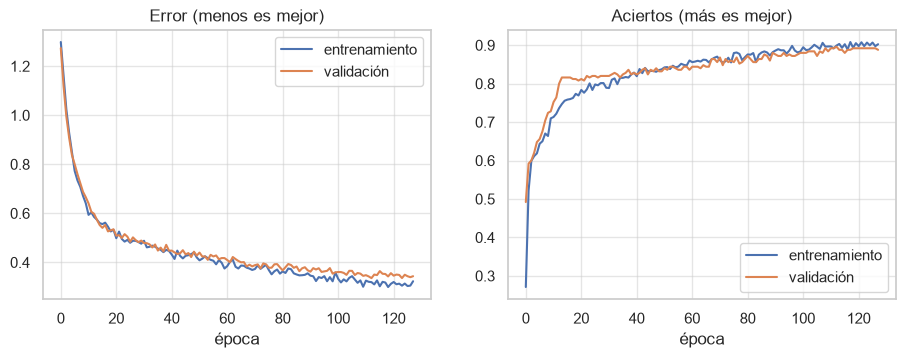

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].plot(historia.history["loss"], label="entrenamiento")
ejes[0].plot(historia.history["val_loss"], label="validación")
ejes[0].set_title("Error (menos es mejor)")
ejes[1].plot(historia.history["accuracy"], label="entrenamiento")
ejes[1].plot(historia.history["val_accuracy"], label="validación")
ejes[1].set_title("Aciertos (más es mejor)")
for eje in ejes:
    eje.set_xlabel("época")
    eje.legend()
plt.show()

El error bajó mucho al principio y después más despacio. Empezó en cerca de 1.3 y en las primeras 10 épocas bajó a más o menos 0.6. Después siguió bajando poco a poco hasta cerca de 0.31 en entrenamiento y 0.34 en validación.
Los aciertos subieron rápido y luego se estabilizaron. Arrancaron muy bajos (cerca de 0.27 en entrenamiento) y en pocas épocas pasaron de 0.6. Hacia la época 20 ya estaban cerca de 0.8 y terminaron en unos 0.90 en entrenamiento y 0.89 en validación.
No hay memorización (overfitting). Las líneas de entrenamiento y de validación van casi pegadas todo el tiempo. Si la red se hubiera aprendido los datos de memoria, el error de entrenamiento seguiría bajando mientras el de validación se separaba y subía, y eso no pasa. La diferencia final es muy pequeña (unos 0.03), lo normal.
Al principio la validación va por encima del entrenamiento. Es normal: durante el entrenamiento el Dropout apaga neuronas a propósito y la red todavía está aprendiendo, mientras que en validación usa todas sus neuronas.
La línea de validación se ve más dentada, porque tiene pocas filas (250), y solo 21 de fumigación focalizada.
El entrenamiento paró solo antes de las 200 épocas (128) gracias a EarlyStopping: el error de validación dejó de mejorar durante 15 épocas seguidas y la red se quedó con su mejor versión.
Conclusión: la red aprende de forma estable y generaliza bien. Pero el porcentaje de aciertos total puede esconder fallos en las acciones raras

Evaluar con los datos de prueba

Qué se analiza: ahora sí usamos la prueba, datos que la red nunca vio. Medimos dos cosas por cada acción:

Precisión: de las veces que la red dijo “fumigación”, ¿cuántas eran correctas?
Recall: de todas las filas que de verdad eran fumigación, ¿cuántas encontró?

La meta es 85 % o más en las dos. La matriz de confusión muestra cada error: las filas son lo correcto y las columnas lo que respondió la red.

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

probabilidades = modelo.predict(X_test_esc, verbose=0)    # 4 probabilidades por fila
y_pred = np.argmax(probabilidades, axis=1)                # se queda con la acción más probable

print(classification_report(y_test, y_pred, target_names=codificador.classes_, digits=2))

                       precision    recall  f1-score   support

     alerta_sanitaria       0.96      0.94      0.95        70
eliminacion_criaderos       0.93      0.79      0.86        72
fumigacion_focalizada       0.90      0.90      0.90        39
     monitoreo_normal       0.93      0.98      0.96       234

             accuracy                           0.93       415
            macro avg       0.93      0.90      0.92       415
         weighted avg       0.93      0.93      0.93       415



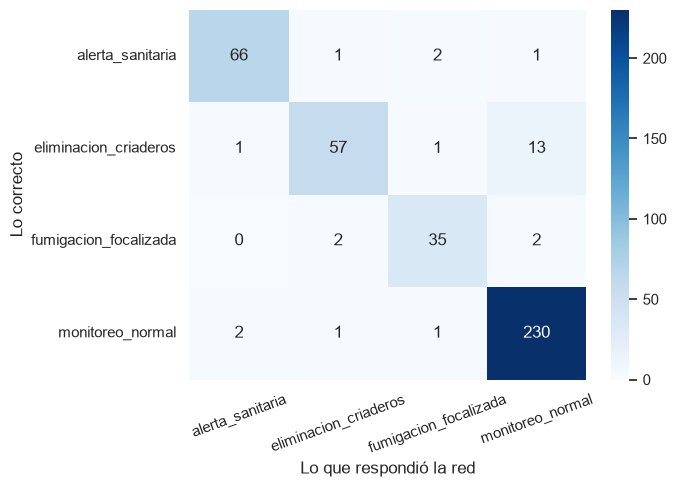

In [19]:
matriz = confusion_matrix(y_test, y_pred)
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
            xticklabels=codificador.classes_, yticklabels=codificador.classes_)
plt.xlabel("Lo que respondió la red")
plt.ylabel("Lo correcto")
plt.xticks(rotation=20)
plt.show()

Aciertos totales: 388 de 415 filas, cerca del 93.5 %.

Precisión: 0.90 o más en las cuatro acciones (alerta 0.96, eliminación 0.93, fumigación 0.90, monitoreo 0.93).

Recall: alerta 0.94, fumigación 0.90 y monitoreo 0.98 cumplen la meta de 85 %.
Eliminación de criaderos queda en 0.79, la única métrica por debajo.

Dónde falla: de las 72 filas de eliminación, 13 se clasificaron como monitoreo normal.

Son las dos acciones más parecidas (en ambas los casos están por debajo del umbral, y solo las separan la lluvia de 80 mm y la temperatura de 27 °C).

La red es cautelosa: casi nunca recomienda eliminación sin razón, pero deja pasar algunos casos reales. Es un punto a mencionar en el informe.

Errores: solo 27 en total, y 15 son de eliminación de criaderos.

Promedio entre las 4 acciones: precisión de unos 0.93 y recall de unos 0.90 (cálculo hecho a partir de la matriz).

Frente a la meta: 7 de las 8 métricas cumplen el 85 %.

Comparación con el primer intento: subimos de 88 % a 93.5 % de aciertos, y la precisión de eliminación pasó de 0.72 a 0.93, a cambio de un recall algo menor (de 0.81 a 0.79).

¿Se puede mejorar? Probar otras redes

Qué se analiza: probamos 4 versiones: una red chica sin pesos, una chica con pesos (la actual) y dos más grandes con pesos. Las comparamos con los datos de validación, no con los de prueba

In [22]:
def entrenar(capas, con_pesos, semilla=42):      # NUEVO: la semilla ahora es un parámetro
    tf.keras.utils.set_random_seed(semilla)       # NUEVO: usa la semilla que le des
    lista = [Input(shape=(X_fit.shape[1],))]          # entrada: 7 números
    for n in capas:
        lista += [Dense(n, activation="relu"), Dropout(0.2)]    # una capa por cada número de la lista
    lista.append(Dense(4, activation="softmax"))      # salida: 4 acciones
    m = Sequential(lista)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(X_fit, y_fit, validation_data=(X_val, y_val), epochs=200, batch_size=32,
          class_weight=pesos_clases if con_pesos else None,      # usa los pesos solo si con_pesos es True
          callbacks=[EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
          verbose=0)
    return m

In [15]:
from sklearn.metrics import f1_score, recall_score

tabla = []
modelos = {}
for capas, con_pesos in [((32, 16), False), ((32, 16), True), ((64, 32), True), ((128, 64), True)]:
    m = entrenar(capas, con_pesos)
    pred = np.argmax(m.predict(X_val, verbose=0), axis=1)          # ojo: con VALIDACIÓN, no con prueba
    recalls = recall_score(y_val, pred, average=None, zero_division=0)
    tabla.append({"capas": str(capas), "con_pesos": con_pesos,
                  "F1_macro": round(f1_score(y_val, pred, average="macro"), 3),
                  "recall_eliminacion": round(recalls[1], 2),
                  "recall_fumigacion": round(recalls[2], 2)})
    modelos[(capas, con_pesos)] = m

pd.DataFrame(tabla)

,capas,con_pesos,F1_macro,recall_eliminacion,recall_fumigacion
0,"(32, 16)",False,0.910,0.76,0.9
1,"(32, 16)",True,0.900,0.92,0.9
2,"(64, 32)",True,0.884,0.92,0.9
3,"(128, 64)",True,0.897,0.89,0.9


In [16]:
print(pd.DataFrame(tabla).to_string())

       capas  con_pesos  F1_macro  recall_eliminacion  recall_fumigacion
0   (32, 16)      False     0.910                0.76                0.9
1   (32, 16)       True     0.900                0.92                0.9
2   (64, 32)       True     0.884                0.92                0.9
3  (128, 64)       True     0.897                0.89                0.9


In [17]:
modelo = modelos[((32, 16), True)]    # la red elegida con los datos de validación

In [20]:
import os
import joblib

modelo.save("../models/ann_acciones.keras")      # la red entrenada
joblib.dump({"columnas": columnas, "escalador": escalador,
             "codificador": codificador, "pesos_clases": pesos_clases},
            "../models/ann_acciones_preprocesado.pkl")    # lo necesario para usarla
print(os.listdir("../models"))

['.gitkeep', 'ann_acciones.keras', 'ann_acciones_preprocesado.pkl', 'ann_columns.pkl', 'ann_control.h5', 'rnn_simple.h5', 'rnn_simple_preprocesado.pkl', 'scaler_ann.pkl']


In [21]:
from tensorflow.keras.models import load_model

cargado = load_model("../models/ann_acciones.keras")    # abre el modelo guardado
y_pred_cargado = np.argmax(cargado.predict(X_test_esc, verbose=0), axis=1)
print("¿Da las mismas respuestas que la red evaluada?", np.array_equal(y_pred, y_pred_cargado))

¿Da las mismas respuestas que la red evaluada? True


Comprobar que el resultado no fue suerte

Qué se analiza: una red neuronal empieza con números al azar, así que cada vez que se entrena da un resultado un poco distinto. La semilla es lo que fija ese azar. Entrenamos la misma red elegida 5 veces con semillas distintas y miramos el promedio y cuánto varía. Si varía poco, el resultado es confiable. Si varía mucho, el 93.5 % pudo ser suerte.

In [23]:
from sklearn.metrics import precision_score, recall_score

resultados_p, resultados_r, aciertos = [], [], []
for semilla in [1, 2, 3, 4, 5]:
    m = entrenar((32, 16), True, semilla)                        # la red elegida, con otra semilla
    pred = np.argmax(m.predict(X_test_esc, verbose=0), axis=1)
    resultados_p.append(precision_score(y_test, pred, average=None, zero_division=0))   # precisión por acción
    resultados_r.append(recall_score(y_test, pred, average=None, zero_division=0))      # recall por acción
    aciertos.append((pred == y_test).mean())                                           # aciertos totales

resumen = pd.DataFrame({
    "precision_promedio": np.mean(resultados_p, axis=0),
    "precision_variacion": np.std(resultados_p, axis=0),
    "recall_promedio": np.mean(resultados_r, axis=0),
    "recall_variacion": np.std(resultados_r, axis=0)}, index=codificador.classes_).round(2)

print("Aciertos: promedio", round(np.mean(aciertos), 3), " variación", round(np.std(aciertos), 3))
resumen

Aciertos: promedio 0.908  variación 0.011


,precision_promedio,precision_variacion,recall_promedio,recall_variacion
alerta_sanitaria,0.95,0.02,0.94,0.01
eliminacion_criaderos,0.82,0.07,0.78,0.02
fumigacion_focalizada,0.86,0.02,0.87,0.03
monitoreo_normal,0.93,0.01,0.94,0.03


Análisis de estabilidad (5 entrenamientos con semillas distintas)

Entrenamos la misma red 5 veces con semillas distintas y calculamos el promedio y la variación de cada métrica sobre los datos de prueba.
Aciertos totales: 90.8 % en promedio, con una variación de 1.1 puntos. La corrida del modelo guardado (93.5 %) fue mejor que el promedio, por lo que el resultado representativo es el 91 %.
alerta_sanitaria y monitoreo_normal son estables y superan el 85 % en precisión y recall (variación de 0.03 o menos).
fumigacion_focalizada cumple la meta, pero por poco (precisión 0.86 y recall 0.87). Con solo 39 filas de prueba, una o dos filas cambian el resultado, y por eso puede quedar justo por debajo en otras corridas.
eliminacion_criaderos no alcanza la meta en promedio: precisión 0.82 y recall 0.78. Además, su precisión es la más inestable (variación de 0.07).
Causa probable: es la acción más parecida a monitoreo normal, y solo las separan reglas de lluvia (80 mm) y temperatura (27 °C), que una red pequeña con 1,645 filas de entrenamiento aprende de forma aproximada.
Frente a la meta: 6 de las 8 métricas cumplen el 85 %. En promedio entre las 4 acciones, la precisión es de 0.89 y el recall de 0.88.
Conclusión: el modelo es confiable para alerta sanitaria y monitoreo, aceptable para fumigación, y su punto débil es eliminación de criaderos. Se declara como limitación en el informe técnico.